# Guía de datos geoespaciales

Lucho Ene | 2025 <br>
The Dumbing Down Of Love by Frou Frou

Esta notebook explica, con ejemplos que podés ejecutar, los conceptos básicos de los datos geoespaciales (o *geo-espaciales*, *GIS*, *datos geográficos*).

**Índice**
1. ¿Qué es un dato geoespacial?
2. Modelo vectorial: puntos, líneas y polígonos
3. Atributos y `GeoDataFrame`
4. Sistemas de coordenadas (CRS) y proyecciones
5. Operaciones espaciales (buffer, distancia, intersección, spatial join…)
6. Modelo raster: grillas, píxeles y bandas
7. Formatos de archivo
8. Mapas interactivos
9. Glosario
10. Ejercicios

### Import Packages | Libraries

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon, MultiPoint

#Raster
import rasterio
from rasterio.transform import from_origin
import folium

### Que es un dato geoespacial?

Un **dato geoespacial** es información que tiene asociada una **ubicación en la Tierra**. Casi siempre combina dos cosas:

| Componente | Responde a | Ejemplo |
|---|---|---|
| **Geometría** (el "dónde") | ¿Dónde está? ¿Qué forma tiene? | Un punto en `(-58.38, -34.60)` |
| **Atributos** (el "qué") | ¿Qué es? ¿Qué propiedades tiene? | `nombre="Obelisco"`, `altura=67.5` |

Hay **dos grandes modelos** para representar el mundo:

- **Vectorial**: objetos discretos definidos por coordenadas (puntos, líneas, polígonos). Ideal para calles, límites, edificios, comercios.
- **Raster**: una grilla de celdas (píxeles), cada una con un valor. Ideal para fenómenos continuos: elevación, temperatura, imágenes satelitales.

### 2. Modelo vectorial: puntos, líneas y polígonos


Las geometrías vectoriales se construyen con la librería **Shapely**. Hay tres tipos básicos:

- **Point**: una ubicación (una parada de colectivo, un hospital).
- **LineString**: una secuencia de puntos conectados (una calle, un río, un recorrido).
- **Polygon**: una línea cerrada que delimita un área (un barrio, un lago, un lote).

Cada una tiene su versión múltiple (`MultiPoint`, `MultiLineString`, `MultiPolygon`) para agrupar varias partes en un solo objeto, por ejemplo un país con islas.

> Convención clave: las coordenadas se escriben como **(x, y) = (longitud, latitud)**. Mucha gente se confunde porque en el habla se dice "latitud, longitud".

In [2]:
# PUNTOS: (longitud, latitud)
obelisco     = Point(-58.3816, -34.6037)
plaza_mayo   = Point(-58.3731, -34.6084)
congreso     = Point(-58.3926, -34.6097)

# LÍNEA: una secuencia de puntos (aprox. Av. de Mayo)
av_de_mayo = LineString([(-58.3731, -34.6084), (-58.3926, -34.6097)])

# POLÍGONO: el primer y último punto se cierran solos
triangulo = Polygon([(-58.3731, -34.6084), (-58.3926, -34.6097), (-58.3816, -34.6037)])

print(obelisco)
print(av_de_mayo)
print(triangulo)

POINT (-58.3816 -34.6037)
LINESTRING (-58.3731 -34.6084, -58.3926 -34.6097)
POLYGON ((-58.3731 -34.6084, -58.3926 -34.6097, -58.3816 -34.6037, -58.3731 -34.6084))


In [3]:
# Propiedades básicas de cada geometría
print("Tipo:            ", obelisco.geom_type, av_de_mayo.geom_type, triangulo.geom_type)
print("Coordenada x,y:  ", obelisco.x, obelisco.y)
print("Largo de la línea (en grados):", round(av_de_mayo.length, 5))
print("Área del polígono (en grados²):", triangulo.area)
print("Bounding box (minx, miny, maxx, maxy):", triangulo.bounds)

Tipo:             Point LineString Polygon
Coordenada x,y:   -58.3816 -34.6037
Largo de la línea (en grados): 0.01954
Área del polígono (en grados²): 5.134999999996955e-05
Bounding box (minx, miny, maxx, maxy): (-58.3926, -34.6097, -58.3731, -34.6037)


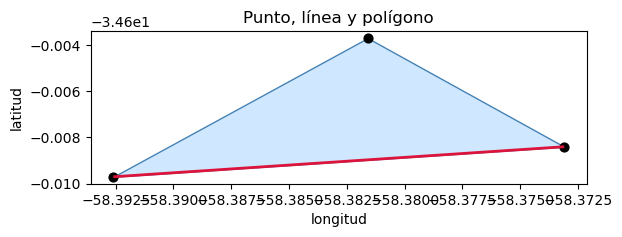

In [4]:
fig, ax = plt.subplots()
gpd.GeoSeries([triangulo]).plot(ax=ax, color="#cfe8ff", edgecolor="steelblue")
gpd.GeoSeries([av_de_mayo]).plot(ax=ax, color="crimson", linewidth=2)
gpd.GeoSeries([obelisco, plaza_mayo, congreso]).plot(ax=ax, color="black", markersize=40)
ax.set_title("Punto, línea y polígono")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
plt.show()

### 3. Atributos y `GeoDataFrame`

Un **GeoDataFrame** (de **GeoPandas**) es un `DataFrame` de pandas con una columna especial llamada `geometry`. Cada fila es una **entidad** (en inglés, *feature*): una geometría más sus atributos.

Si sabés usar pandas, ya sabés usar GeoPandas: filtros, `groupby`, `merge`, etc. funcionan igual.

In [5]:
lugares = gpd.GeoDataFrame(
    {
        "nombre": ["Obelisco", "Plaza de Mayo", "Congreso"],
        "tipo": ["monumento", "plaza", "edificio público"],
        "visitas_dia": [20000, 35000, 8000],
    },
    geometry=[obelisco, plaza_mayo, congreso],
    crs="EPSG:4326",   # ← sistema de coordenadas (ver sección 4)
)
lugares

,nombre,tipo,visitas_dia,geometry
0,Obelisco,monumento,20000,POINT (-58.3816 -34.6037)
1,Plaza de Mayo,plaza,35000,POINT (-58.3731 -34.6084)
2,Congreso,edificio público,8000,POINT (-58.3926 -34.6097)


In [6]:
# Se filtra como cualquier DataFrame
lugares[lugares["visitas_dia"] > 10000]

,nombre,tipo,visitas_dia,geometry
0,Obelisco,monumento,20000,POINT (-58.3816 -34.6037)
1,Plaza de Mayo,plaza,35000,POINT (-58.3731 -34.6084)


**Vocabulario rápido**

- **Feature / entidad**: cada fila (un lugar, una calle, un barrio).
- **Capa (layer)**: un conjunto de features del mismo tipo (la capa de "calles", la de "hospitales").
- **Tabla de atributos**: todas las columnas que no son la geometría.
- **Metadatos**: información *sobre* el dato (quién lo creó, cuándo, con qué precisión, qué CRS usa).

### 4. Sistemas de coordenadas (CRS) y proyecciones

Este es el concepto que más confunde, y el que más errores causa.

### ¿Qué es un CRS?
Un **CRS** (*Coordinate Reference System*, o sistema de referencia de coordenadas) define **cómo los números de una coordenada se corresponden con un lugar real**. Sin CRS, `(-58.38, -34.60)` es solo un par de números.

Hay dos familias:

| Tipo | Unidades | Qué es | Ejemplo |
|---|---|---|---|
| **Geográfico** | grados (°) | Coordenadas sobre una esfera/elipsoide: latitud y longitud | `EPSG:4326` (WGS 84, el de GPS) |
| **Proyectado** | metros (u otras) | Coordenadas sobre un plano, "aplastando" la Tierra | `EPSG:3857` (Web Mercator), UTM, Gauss-Krüger |

### Piezas relacionadas
- **Datum**: el modelo de la forma de la Tierra al que se ancla el sistema (WGS 84, POSGAR, etc.).
- **Elipsoide**: la figura matemática aproximada de la Tierra (achatada en los polos).
- **Proyección**: la fórmula que pasa de la superficie curva a un plano. **Toda proyección distorsiona algo**: áreas, distancias, ángulos o formas.
- **Código EPSG**: un número que identifica un CRS de forma estándar (el "DNI" del sistema de coordenadas).

### CRS que vas a ver seguido
| EPSG | Nombre | Cuándo se usa |
|---|---|---|
| `4326` | WGS 84 (lat/lon) | GPS, GeoJSON, intercambio de datos |
| `3857` | Web Mercator | Mapas web (Google Maps, OpenStreetMap). **No sirve para medir**: distorsiona mucho el área |
| `5347` | POSGAR 2007 / Argentina faja 5 | Mediciones en Buenos Aires, en metros (hay fajas 1 a 7 en todo el país) |
| `4326` → UTM | UTM zona 20S/21S | Mediciones en metros en gran parte de Argentina |

> 🔑 **Regla de oro**: para medir distancias o áreas, **reproyectá a un CRS proyectado en metros**. Medir en grados da números sin sentido.

In [7]:
print(lugares.crs)
print("¿Es geográfico?", lugares.crs.is_geographic)

EPSG:4326
¿Es geográfico? True


In [8]:
# Distancia entre el Obelisco y Plaza de Mayo, en los dos CRS
a, b = lugares.geometry.iloc[0], lugares.geometry.iloc[1]

print("En EPSG:4326 (grados):", a.distance(b))   # ← un número sin interpretación práctica

lugares_m = lugares.to_crs("EPSG:5347")          # reproyectar a metros
a_m, b_m = lugares_m.geometry.iloc[0], lugares_m.geometry.iloc[1]
print("En EPSG:5347 (metros):", round(a_m.distance(b_m), 1), "m")

En EPSG:4326 (grados): 0.00971287804926853
En EPSG:5347 (metros): 938.2 m


In [9]:
# Así cambian las coordenadas del mismo punto según el CRS
print("EPSG:4326 :", lugares.geometry.iloc[0])
print("EPSG:5347 :", lugares_m.geometry.iloc[0])

EPSG:4326 : POINT (-58.3816 -34.6037)
EPSG:5347 : POINT (5648456.72233061 6170146.884900631)


`set_crs` vs `to_crs`: no son lo mismo

- **`set_crs(...)`**: *etiqueta* los datos cuando no tienen CRS y vos **sabés** en cuál están. No cambia los números.
- **`to_crs(...)`**: **transforma** las coordenadas de un CRS a otro. Cambia los números.

Confundirlos es la causa #1 de capas que "aparecen en el océano" o a miles de kilómetros de donde deberían.

### 5. Operaciones espaciales

Una de las grandes ventajas de los datos geoespaciales es que podés hacerles preguntas *espaciales*.

| Operación | Qué hace |
|---|---|
| **Buffer** | Crea una zona de influencia a una distancia dada alrededor de una geometría |
| **Centroide** | El centro geométrico de una forma |
| **Distance** | Distancia entre dos geometrías |
| **Intersects / Within / Contains** | Relaciones topológicas (¿se tocan? ¿está adentro?) |
| **Intersection / Union / Difference** | Operaciones de superposición (*overlay*) |
| **Spatial join** | Une tablas según su relación espacial, no según una clave |
| **Dissolve** | Agrupa geometrías por un atributo y las fusiona |
| **Clip** | Recorta una capa con otra |

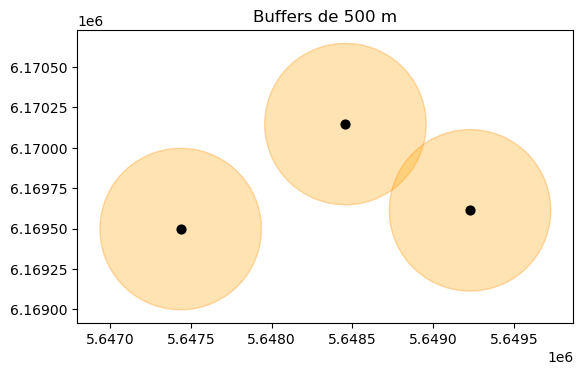

In [10]:
# BUFFER: zona de 500 metros alrededor de cada lugar (¡en un CRS en metros!)
buffers = lugares_m.copy()
buffers["geometry"] = lugares_m.buffer(500)

fig, ax = plt.subplots()
buffers.plot(ax=ax, alpha=0.3, color="orange", edgecolor="darkorange")
lugares_m.plot(ax=ax, color="black", markersize=40)
ax.set_title("Buffers de 500 m")
plt.show()

In [11]:
# CENTROIDE y ÁREA (en metros cuadrados)
tri_m = gpd.GeoSeries([triangulo], crs="EPSG:4326").to_crs("EPSG:5347")
print("Área:", round(tri_m.area.iloc[0]), "m²")
print("Centroide:", tri_m.centroid.to_crs("EPSG:4326").iloc[0])

Área: 522799 m²
Centroide: POINT (-58.38243325577248 -34.60726692655597)


In [12]:
# RELACIONES ESPACIALES: ¿qué lugares caen dentro de los buffers de OTRO lugar?
zona_obelisco = lugares_m.geometry.iloc[0].buffer(1000)   # 1 km
lugares_m["a_menos_de_1km_del_obelisco"] = lugares_m.within(zona_obelisco)
lugares_m[["nombre", "a_menos_de_1km_del_obelisco"]]

,nombre,a_menos_de_1km_del_obelisco
0,Obelisco,True
1,Plaza de Mayo,True
2,Congreso,False


In [13]:
# INTERSECCIÓN entre dos buffers
buf_obelisco = lugares_m.geometry.iloc[0].buffer(800)
buf_congreso = lugares_m.geometry.iloc[2].buffer(800)
inter = buf_obelisco.intersection(buf_congreso)
print("¿Se superponen?", buf_obelisco.intersects(buf_congreso))
print("Área de superposición:", round(inter.area), "m²")

¿Se superponen? True
Área de superposición: 279129 m²


#### Spatial join

En una tabla normal unís por una **clave** (ej: `id`). En un *spatial join* unís por **ubicación**: "a cada punto, asignale el polígono donde cae". Es muy útil para, por ejemplo, saber en qué barrio está cada comercio.

In [14]:
# Dos "barrios" inventados como polígonos
barrios = gpd.GeoDataFrame(
    {"barrio": ["Zona Norte", "Zona Sur"]},
    geometry=[
        Polygon([(-58.40, -34.605), (-58.36, -34.605), (-58.36, -34.595), (-58.40, -34.595)]),
        Polygon([(-58.40, -34.615), (-58.36, -34.615), (-58.36, -34.605), (-58.40, -34.605)]),
    ],
    crs="EPSG:4326",
)

# ¿En qué barrio cae cada lugar?
gpd.sjoin(lugares, barrios, how="left", predicate="within")[["nombre", "barrio"]]

,nombre,barrio
0,Obelisco,Zona Norte
1,Plaza de Mayo,Zona Sur
2,Congreso,Zona Sur


### 6. Modelo raster: grillas, píxeles y bandas

Un **raster** es una matriz de números (como una imagen) donde cada celda representa una porción cuadrada del terreno.

**Conceptos clave**

- **Píxel / celda**: una unidad de la grilla, con un valor.
- **Resolución espacial**: el tamaño del terreno que cubre un píxel (ej: 30 m → cada píxel cubre 30×30 m). Menor número = más detalle.
- **Bandas**: capas de valores apiladas. Una foto RGB tiene 3 (rojo, verde, azul); un satélite como Sentinel-2 tiene 13.
- **Georreferenciación (transform)**: la información que ubica la grilla en el mundo (coordenada de la esquina superior izquierda + tamaño de píxel).
- **NoData**: valor reservado para "sin dato" (nubes, fuera del área).
- **DEM / MDE (Modelo Digital de Elevación)**: un raster donde cada valor es una altura.

Ejemplos típicos: elevación, temperatura, precipitación, imágenes satelitales, uso del suelo.

In [15]:
# Un "DEM" inventado de 100x100 píxeles: una colina con ruido
x, y = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-3, 3, 100))
dem = 200 * np.exp(-(x**2 + y**2) / 2) + np.random.default_rng(0).normal(0, 3, x.shape)
dem = dem.astype("float32")

# Georreferenciación: esquina superior izquierda (lon, lat) y tamaño de píxel en grados
transform = from_origin(-58.45, -34.55, 0.001, 0.001)

print("Forma de la matriz (filas, columnas):", dem.shape)
print("Valor mínimo / máximo:", dem.min().round(1), dem.max().round(1))

Forma de la matriz (filas, columnas): (100, 100)
Valor mínimo / máximo: -11.2 204.6


CRS:        EPSG:4326
Bandas:     1
Tamaño:     100 x 100 píxeles
Resolución: (0.001, 0.001)
Extensión:  BoundingBox(left=-58.45, bottom=-34.65, right=-58.35, top=-34.55)
NoData:     -9999.0


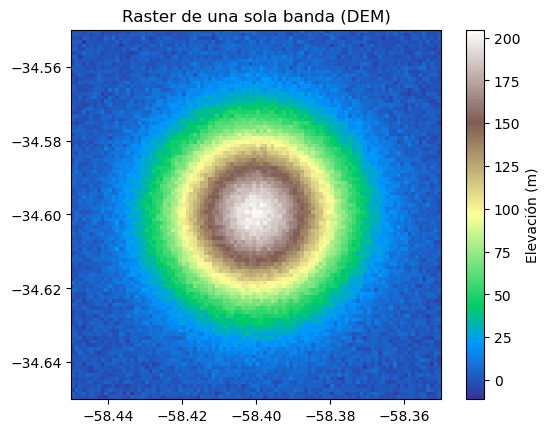

In [16]:
with rasterio.open(
    "dem_ejemplo.tif", "w", driver="GTiff",
    height=dem.shape[0], width=dem.shape[1], count=1,   # count = cantidad de bandas
    dtype="float32", crs="EPSG:4326", transform=transform, nodata=-9999,
) as dst:
    dst.write(dem, 1)

with rasterio.open("dem_ejemplo.tif") as src:
    print("CRS:       ", src.crs)
    print("Bandas:    ", src.count)
    print("Tamaño:    ", src.width, "x", src.height, "píxeles")
    print("Resolución:", src.res)
    print("Extensión: ", src.bounds)
    print("NoData:    ", src.nodata)
    datos = src.read(1)
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

plt.imshow(datos, cmap="terrain", extent=extent)
plt.colorbar(label="Elevación (m)")
plt.title("Raster de una sola banda (DEM)")
plt.show()

In [17]:
# Consultar el valor del raster en un punto del mundo real
with rasterio.open("dem_ejemplo.tif") as src:
    valor = next(src.sample([(-58.40, -34.60)]))[0]
print("Elevación en (-58.40, -34.60):", round(float(valor), 1), "m")

Elevación en (-58.40, -34.60): 201.4 m


#### Vector vs. raster: ¿cuál uso?

| | Vectorial | Raster |
|---|---|---|
| **Representa** | Objetos con forma definida | Superficies continuas |
| **Estructura** | Coordenadas + atributos | Grilla de píxeles |
| **Ejemplos** | Calles, parcelas, límites, comercios | Elevación, clima, imágenes satelitales |
| **Escala** | Nítido a cualquier zoom | Se pixela al acercarse |
| **Tamaño** | Chico (depende de los vértices) | Puede ser enorme (depende de la resolución) |
| **Formatos** | GeoJSON, Shapefile, GeoPackage | GeoTIFF, NetCDF, JPEG2000 |

Se pueden combinar: por ejemplo, calcular la elevación media (raster) dentro de cada barrio (vector). Eso se llama **estadística zonal**.

### 7. Formatos de archivo

| Formato | Extensión | Tipo | Notas |
|---|---|---|---|
| **GeoJSON** | `.geojson` | Vector | Texto, legible, estándar web. Siempre en EPSG:4326 |
| **Shapefile** | `.shp` (+ `.shx`, `.dbf`, `.prj`…) | Vector | El clásico de Esri. Son **varios archivos juntos**. Nombres de columna de máx. 10 caracteres |
| **GeoPackage** | `.gpkg` | Vector (y raster) | Un solo archivo SQLite. Recomendado hoy como reemplazo del shapefile |
| **GeoParquet** | `.parquet` | Vector | Columnar, muy rápido para datos grandes |
| **KML / KMZ** | `.kml` | Vector | Usado por Google Earth |
| **CSV con lat/lon** | `.csv` | Puntos | Simple, pero hay que construir la geometría a mano |
| **GeoTIFF** | `.tif` | Raster | Estándar de raster con georreferenciación |
| **NetCDF** | `.nc` | Raster multidimensional | Común en clima y oceanografía |
| **COG** | `.tif` | Raster | *Cloud Optimized GeoTIFF*: se puede leer por partes desde la nube |

In [18]:
# Escribir y leer
lugares.to_file("lugares.geojson", driver="GeoJSON")
lugares.to_file("lugares.gpkg", driver="GPKG")

releido = gpd.read_file("lugares.gpkg")
releido

,nombre,tipo,visitas_dia,geometry
0,Obelisco,monumento,20000,POINT (-58.3816 -34.6037)
1,Plaza de Mayo,plaza,35000,POINT (-58.3731 -34.6084)
2,Congreso,edificio público,8000,POINT (-58.3926 -34.6097)


In [19]:
# CSV con latitud y longitud → GeoDataFrame
df = pd.DataFrame({
    "nombre": ["Estación Haedo", "Estación Once"],
    "lat": [-34.6436, -34.6089],
    "lon": [-58.5942, -58.4060],
})
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326"
)
gdf

,nombre,lat,lon,geometry
0,Estación Haedo,-34.6436,-58.5942,POINT (-58.5942 -34.6436)
1,Estación Once,-34.6089,-58.4060,POINT (-58.406 -34.6089)


### 8. Mapas interactivos

Para ver las capas sobre un mapa base con zoom y *popups*, se usa **Folium** (basado en Leaflet). Los mapas web trabajan en `EPSG:4326` para los datos de entrada, y los muestran internamente en Web Mercator.

In [20]:
m = folium.Map(location=[-34.607, -58.385], zoom_start=14)
for _, fila in lugares.iterrows():
    folium.Marker(
        [fila.geometry.y, fila.geometry.x],   # folium usa (lat, lon)
        popup=f"{fila['nombre']} ({fila['tipo']})",
    ).add_to(m)

folium.GeoJson(triangulo.__geo_interface__, style_function=lambda f: {"color": "steelblue"}).add_to(m)

### Resumen

| Término | Significado |
|---|---|
| **GIS / SIG** | Sistema de Información Geográfica: software o conjunto de herramientas para manejar datos geoespaciales |
| **Geometría** | La forma y ubicación de una entidad (punto, línea, polígono) |
| **Feature** | Una entidad: geometría + atributos |
| **Capa (layer)** | Conjunto de features temáticamente relacionadas |
| **CRS / SRS** | Sistema de referencia de coordenadas |
| **EPSG** | Código numérico estándar que identifica un CRS |
| **Datum** | Modelo de referencia de la forma de la Tierra |
| **Proyección** | Método para representar la Tierra curva en un plano |
| **WGS 84** | Datum global usado por el GPS |
| **POSGAR** | Sistema geodésico oficial de Argentina |
| **Gauss-Krüger** | Proyección usada en Argentina, dividida en 7 fajas |
| **Geocodificación** | Convertir una dirección ("Av. Corrientes 1000") en coordenadas |
| **Geocodificación inversa** | Convertir coordenadas en una dirección |
| **Topología** | Reglas de relación entre geometrías (adyacencia, superposición, conexión) |
| **Bounding box / extent** | El rectángulo mínimo que contiene una geometría o capa |
| **Buffer** | Zona alrededor de una geometría a cierta distancia |
| **Overlay** | Superposición de capas (intersección, unión, diferencia) |
| **Spatial join** | Unión de tablas por relación espacial |
| **Resolución** | Tamaño de terreno que cubre un píxel |
| **Banda** | Una capa de valores dentro de un raster |
| **DEM / MDE** | Modelo digital de elevación |
| **NoData** | Valor que indica ausencia de dato en un raster |
| **Teledetección** | Obtención de datos de la Tierra a distancia (satélites, drones) |
| **Estadística zonal** | Resumir valores de un raster dentro de polígonos |
| **Metadatos** | Datos que describen a los datos |

#### Extra:

Ejercicios

1. Creá un `GeoDataFrame` con 5 lugares que conozcas (nombre + coordenadas) y mostralos en un mapa de Folium.
2. Calculá la distancia en metros entre dos de ellos usando `EPSG:5347`. Compará con el resultado en grados.
3. Hacé un buffer de 1 km alrededor de uno y averiguá cuáles de los otros caen adentro.
4. Guardá tu capa en GeoPackage y volvé a leerla.
5. Creá un raster pequeño con `numpy` y guardalo como GeoTIFF con `rasterio`.

**Para seguir aprendiendo**: la documentación de [GeoPandas](https://geopandas.org), [Shapely](https://shapely.readthedocs.io), [Rasterio](https://rasterio.readthedocs.io) y el sitio [epsg.io](https://epsg.io) para buscar CRS.